In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "2"

# Кластеризация

**Цель работы:**

Изучение алгоритмов и методов кластеризации на практике.

### Часть 1 
#### 1.1    Генерация и предобработка набора данных
Функция создаёт DataFrame с 3 группами по n объектов каждая и признаками x и y.

In [2]:
import numpy as np
import pandas as pd

def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3],
                             [6, 9],
                             [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)    # оси 1 и 2 поменяны местами: группа - объект - координата
    data = data.reshape((-1, 2))    # вместо двух осей - одна ось длиной в 3n точек 
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]},
                      columns=['x', 'y'])
    df = df.sample(frac=1.0)    # перемешивание групп
    return df

`shift_matrix` это двумерный массив формы (3, 2). `randn` генерирует трехмерную выборку из стандартного нормального распределения (современный подход через `standart_normal`) размером (3, 2, n). Далее полученный "шум" вокруг нуля сдвигается за счёт прибавления матрицы сдвига `shift_matrix`, при сложении NumPy «растягивает» этот массив по последней оси (по n). В результате внутри первой группы к первой координате прибавляется 3, ко второй тоже 3; во второй группе соответственно +6, +9; в третьей +9, +3.   
Метод `df.sample(frac=1.0)` возвращает случайную выборку строк DataFrame. При этом параметр `frac=1.0` означает долю, в данном случае 100 % строк.   

In [3]:
df = make_data(100, 15)
display(df)
# df.describe()

,x,y
43,46.649670,1.300508
127,114.602554,4.582664
200,213.764482,0.699972
107,129.418887,3.930599
68,67.100921,1.558457
...,...,...
185,86.340169,4.453972
111,143.422477,4.492222
287,175.091372,2.246279
254,172.469148,1.431849


Перед обучением стандартизация данных **обязательна**, поэтому используется отдельная структура StandardScaler модуля sklearn.preprocessing:

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # создание объекта класса Scaler
scaler.fit(df) # обучение стандартизатора - вычисление mean и std
print(scaler.mean_)   # массив средних по каждому столбцу
print(scaler.scale_)
df_scaled = scaler.transform(df) # преобразование данных 
pd.DataFrame(df_scaled).describe()

[120.13466692   2.46690399]
[53.5790133   1.48142831]


,0,1
count,3.000000e+02,3.000000e+02
mean,4.144833e-17,1.065814e-16
std,1.001671e+00,1.001671e+00
min,-2.134585e+00,-1.822588e+00
25%,-9.006507e-01,-7.567074e-01
50%,7.775064e-03,-4.751663e-01
75%,8.643784e-01,1.097240e+00
max,1.911644e+00,2.274045e+00


Значение `mean ≈ 0`, а `std ≈ 1`, значит стандартизаци прошла успешно и оба признака **сопоставимы по масштабу**. 

#### 1.2    Кластеризация методом k-means
Алгоритм K-средних является одним из наиболее простых и широко используемых методов кластеризации. Он основывается на идее разделения данных на K кластеров, где K — заданное число кластеров. Этот метод чувствителен к числу кластеров и основан на предположении, что *число групп известно заранее*.   
Итерационно алгоритм перемещает центроиды кластеров в такие точки пространства данных, которые минимизируют суммарное расстояние от всех точек данных до центроидов. Этот процесс продолжается до тех пор, пока центроиды больше не меняются, или достигнута максимальная заданная точность.   
Для реализации данного алгоритма в Python используется `Kmeans`. 

In [5]:
from sklearn.cluster import KMeans
import os

os.environ["OMP_NUM_THREADS"] = "2"

k_means = KMeans(n_clusters=3, random_state=15)  # random_state для воспроизводимости деления на кластеры
clusters = k_means.fit_predict(df_scaled)          # формирование вектора с метками кластеров

Теперь для каждой строки из df_scaled указан номер кластера: 0, 1 или 2. 

In [6]:
# метки кластеров
print(clusters)                 

[0 1 2 1 0 1 0 1 1 0 1 2 1 1 0 2 0 2 1 2 1 0 0 2 1 1 0 0 1 2 1 2 2 2 0 0 2
 2 0 1 1 1 0 2 2 2 0 2 0 0 1 0 1 1 2 2 2 2 0 1 0 0 1 2 2 1 2 2 0 0 1 2 1 0
 1 0 2 2 0 0 0 1 0 1 0 1 2 2 1 2 1 0 1 1 1 0 2 0 0 1 1 2 0 2 0 0 2 1 0 1 0
 1 1 2 1 2 1 1 0 1 0 0 2 2 2 1 2 1 1 1 1 1 1 1 0 0 1 1 1 1 1 2 0 0 0 1 0 2
 2 2 2 0 2 1 0 2 2 1 0 2 2 2 2 1 2 2 2 0 1 0 2 2 2 2 2 2 1 1 2 2 1 1 0 1 2
 1 1 0 0 0 0 2 0 2 2 2 0 0 2 0 0 2 2 0 1 2 2 0 0 1 1 2 0 2 0 0 1 2 0 2 2 1
 1 1 0 0 0 2 1 2 1 1 1 2 2 1 0 2 0 0 1 0 1 0 0 1 2 0 1 1 2 2 1 1 0 1 1 0 0
 1 2 2 1 0 0 1 0 0 2 2 0 2 1 2 2 1 2 0 1 2 2 2 0 2 0 0 0 0 0 0 0 0 1 1 0 1
 1 2 2 0]


Для визуализации кластеров используется диаграмма рассеивания (scatter). 

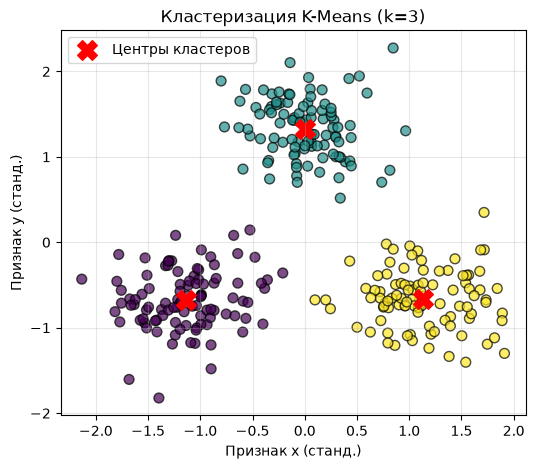

In [7]:
import matplotlib.pyplot as plt

# диаграмма по стандартизованным данным, метка кластера -> цвет
plt.figure(figsize=(6, 5))
plt.scatter(df_scaled[:, 0], df_scaled[:, 1], 
            c=clusters, cmap='viridis', s=50, alpha=0.7, edgecolors='k')

# центры кластеров
centers = k_means.cluster_centers_    # тоже numpy-массив формы (k, 2)

# первые 2 аргумента - одномерные массивы одинаковой длины
plt.scatter(centers[:, 0], centers[:, 1], 
            c='red', s=200, marker='X', label='Центры кластеров')

plt.xlabel('Признак x (станд.)')
plt.ylabel('Признак y (станд.)')
plt.title('Кластеризация K-Means (k=3)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Точки, принадлежащие одному кластеру, окрашены в один цвет и располагаются около соответствующих центров (красных крестиков). Визуально наблюдается три хорошо разделённых группы, что свидетельствует о корректной работе алгоритма k-means при k=3.

#### 1.3    Оценка качества кластеризации 
Одной из внутренних метрик (нет заранее известного разделения на классы) качества является **коэффициент силуэта**. Он принимает значения в диапазоне (-1; 1) и показывает, насколько объект похож на другие объекты своего кластера.    
Силуэт объекта $i$ вычисляется по формуле:$$S_i = \frac{b_i - a_i}{\max(a_i, b_i)},$$где
$a_i$ — среднее расстояние между объектом $i$ и другими объектами того же кластера;
$b_i$ — наименьшее среднее расстояние между объектом $i$ и объектами всех других кластеров.   
Интерпретация:   
- если $S_i > 0$, то в среднем точки своего кластера ближе, чем точки из других кластеров ($b_i > a_i$);
- если $S_i < 0$, то ситуация обратная — объект ближе к чужому кластеру, чем к своему;
- значение, близкое к 1, означает хорошую кластеризацию объекта;
- значение, близкое к −1, означает неудачную кластеризацию объекта.
  
Силуэт выборки — средняя величина силуэта объектов данной выборки. Он показывает общее качество кластеризации и также лежит в диапазоне от −1 до +1. Значение около 0 указывает на перекрывающиеся кластеры.

In [8]:
from sklearn.metrics import silhouette_score

sil_3 = silhouette_score(df_scaled, clusters)
print(f"Силуэт для k=3: {sil_3:.4f}")

Силуэт для k=3: 0.7043


Полученное значение коэффициента силуэта (≈ 0.7) заметно больше 0 и достаточно близко к 1, то есть в среднем объекты находятся ближе к точкам своего кластера, чем к точкам других кластеров ($a_i < b_i$). Можно сказать, что полученные кластеры компактны и хорошо разделены.   
#### 1.4 Обучение модели для k=2 и k=4

Силуэт для k=2: 0.4716
Силуэт для k=4: 0.5578


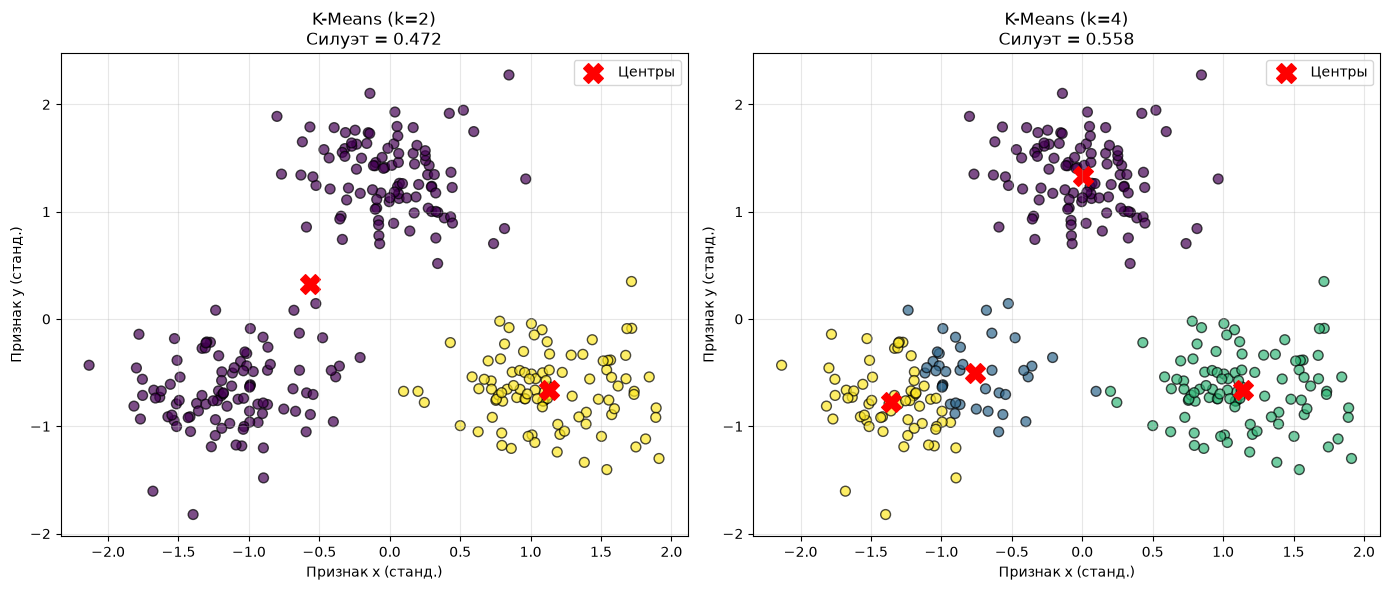

In [9]:
k_means_2 = KMeans(n_clusters=2, random_state=10)  
clusters_2 = k_means_2.fit_predict(df_scaled)    
sil_2 = silhouette_score(df_scaled, clusters_2)

k_means_4 = KMeans(n_clusters=4, random_state=20)  
clusters_4 = k_means_4.fit_predict(df_scaled)    
sil_4 = silhouette_score(df_scaled, clusters_4)
print(f"Силуэт для k=2: {sil_2:.4f}")
print(f"Силуэт для k=4: {sil_4:.4f}")

#___________визуализация___________
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График для k=2
axes[0].scatter(df_scaled[:, 0], df_scaled[:, 1],
                c=clusters_2, cmap='viridis', s=50, alpha=0.7, edgecolors='k')
centers_2 = k_means_2.cluster_centers_
axes[0].scatter(centers_2[:, 0], centers_2[:, 1],
                c='red', s=200, marker='X', label='Центры')
axes[0].set_title(f'K-Means (k=2)\nСилуэт = {sil_2:.3f}')
axes[0].set_xlabel('Признак x (станд.)')
axes[0].set_ylabel('Признак y (станд.)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# График для k=4
axes[1].scatter(df_scaled[:, 0], df_scaled[:, 1],
                c=clusters_4, cmap='viridis', s=50, alpha=0.7, edgecolors='k')
centers_4 = k_means_4.cluster_centers_
axes[1].scatter(centers_4[:, 0], centers_4[:, 1],
                c='red', s=200, marker='X', label='Центры')
axes[1].set_title(f'K-Means (k=4)\nСилуэт = {sil_4:.3f}')
axes[1].set_xlabel('Признак x (станд.)')
axes[1].set_ylabel('Признак y (станд.)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Все значения метрики положительные, то есть в среднем объекты ближе к своему кластеру, чем к чужим. Однако максимальное качество всё же достигается при k = 3.    
**k = 2**   
Фиолетовый кластер объединяет две хорошо различимые группы точек (верхнюю и нижнюю левую). Центр этого кластера оказывается между ними, поэтому внутрикластерные расстояния большие. Жёлтый кластер почти совпадает с одним из кластеров при k=3 и выглядит компактным. В итоге силуэт заметно ниже, чем при правильном числе кластеров.   
**k = 4**   
Один из плотных кластеров (фиолетовый при k=3) искусственно разделён на два. Эти два новых кластера перекрываются и мало отличаются друг от друга по расположению точек. Остальные два кластера совпадают с голубым и желтым кластерами при k=3. Из-за избыточного разбиения качество падает по сравнению с k=3.

#### 1.5 Метод локтя
Наилучшее разбиение получено при k = 3: максимальный коэффициент силуэта (≈ 0.70) и визуально чёткие, компактные и хорошо разделённые кластеры.

При k=2 происходит недоразбиение (две естественные группы объединяются в одну), при k=4 — переразбиение (один естественный кластер делится на два перекрывающихся). Оба случая дают более низкое значение силуэта.

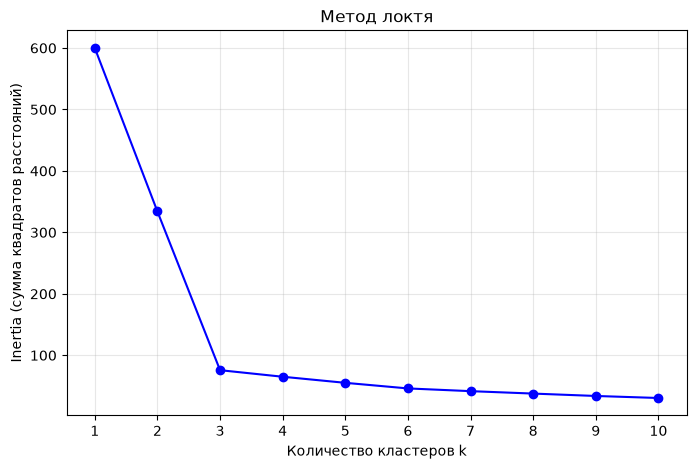

In [10]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=15, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Количество кластеров k')
plt.ylabel('Inertia (сумма квадратов расстояний)')
plt.title('Метод локтя')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.show()

На графике метода локтя наблюдается характерный излом при k = 3. Дальнейшее увеличение числа кластеров даёт лишь незначительное уменьшение distortion score. Это подтверждает, что оптимальное количество кластеров равно 3, что согласуется с максимальным значением коэффициента силуэта.

### Часть 2

Вариант №1 

Набор данных: датасет medical_diagnosis.csv содержит информацию о болезнях.   
Атрибуты:
- age — возраст пациента (лет), числовой.
- sex — пол: Male / Female, категориальный.
- BMI — индекс массы тела (кг/м²), числовой.
- systolic_bp — систолическое артериальное давление, мм рт. ст., числовой.
- cholesterol_mg_dl — общий холестерин сыворотки, мг/дл, числовой.
- fasting_glucose_mg_dl — глюкоза крови натощак, мг/дл, числовой.
- smoking_status — статус курения: Never / Former / Current, категориальный.
- family_history — наследственность по заболеванию: Yes / No, категориальный.
- activity_level — уровень физической активности: Low / Moderate / High, категориальный.
- symptom_score — суммарная выраженность симптомов (0–10), числовой.
- CRP_mg_L — С-реактивный белок, мг/л (маркер воспаления), числовой.
- WBC_10e9_L — лейкоциты, ×10⁹/л, числовой.
- ECG_result — результат ЭКГ: Normal / ST-T abnormality / LVH, категориальный.
- Disease — целевой класс: 1 — болеет, 0 — не болеет.

In [13]:
df_med = pd.read_csv('medical_diagnosis.csv') # чтение данных из файла
df_med.head()

,age,sex,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,CRP_mg_L,WBC_10e9_L,ECG_result,Disease
0,34,Male,16.8,132.0,196.0,78.0,Current,No,High,0.2,0.58,8.60,Normal,0
1,24,Female,29.2,118.0,182.0,96.0,Current,No,Moderate,3.2,2.72,6.54,Normal,0
2,19,Female,16.5,121.0,268.0,101.0,Current,No,Moderate,3.8,0.18,6.61,Normal,0
3,89,Female,15.4,117.0,136.0,96.0,Never,No,Low,2.6,1.83,5.67,Normal,0
4,66,Male,16.7,82.0,241.0,126.0,Former,No,Moderate,3.5,1.16,2.66,Normal,0


In [14]:
df_med.info()

<class 'pandas.DataFrame'>
RangeIndex: 3031 entries, 0 to 3030
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3031 non-null   int64  
 1   sex                    3031 non-null   str    
 2   BMI                    3031 non-null   float64
 3   systolic_bp            3031 non-null   float64
 4   cholesterol_mg_dl      3031 non-null   float64
 5   fasting_glucose_mg_dl  3031 non-null   float64
 6   smoking_status         3031 non-null   str    
 7   family_history         3031 non-null   str    
 8   activity_level         3031 non-null   str    
 9   symptom_score          3031 non-null   float64
 10  CRP_mg_L               3031 non-null   float64
 11  WBC_10e9_L             3031 non-null   float64
 12  ECG_result             3031 non-null   str    
 13  Disease                3031 non-null   int64  
dtypes: float64(7), int64(2), str(5)
memory usage: 408.9 KB


Всего таблица содержит 3030 строк, пропущенных значений нет. Типы данных сопоставимы с описанием датасета.

In [18]:
print(df_med.duplicated().sum()) # подсчет количества дубликатов

1


In [19]:
df_med = df_med.drop_duplicates().reset_index(drop=True)
print(df_med.duplicated().sum()) # подсчет количества дубликатов

0


Удалена строка-дубликат. Теперь нужно проверить датасет на наличие неявных дубликатов для категориальных данных:

In [22]:
df_med.columns

Index(['age', 'sex', 'BMI', 'systolic_bp', 'cholesterol_mg_dl',
       'fasting_glucose_mg_dl', 'smoking_status', 'family_history',
       'activity_level', 'symptom_score', 'CRP_mg_L', 'WBC_10e9_L',
       'ECG_result', 'Disease'],
      dtype='str')

In [26]:
df_med['sex'].value_counts() # вывод уникальных значений и их частоты

sex
Male      1526
Female    1504
Name: count, dtype: int64

In [27]:
df_med['smoking_status'].value_counts() # вывод уникальных значений и их частоты

smoking_status
Never      1540
Former      922
Current     568
Name: count, dtype: int64

In [28]:
df_med['family_history'].value_counts() # вывод уникальных значений и их частоты

family_history
No     2009
Yes    1021
Name: count, dtype: int64

In [29]:
df_med['activity_level'].value_counts() # вывод уникальных значений и их частоты

activity_level
Moderate    1369
Low         1050
High         611
Name: count, dtype: int64

In [30]:
df_med['ECG_result'].value_counts() # вывод уникальных значений и их частоты

ECG_result
Normal              2381
ST-T abnormality     531
LVH                  118
Name: count, dtype: int64

In [31]:
df_med['Disease'].value_counts() # вывод уникальных значений и их частоты

Disease
0    2981
1      49
Name: count, dtype: int64

Все категориальные данные имеют значения согласно заявленным в описании датасета, неявных дубликатов нет. Осталось проверить числовые данные датасета на выбросы:

In [32]:
df_med.describe()

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L,Disease
count,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000
mean,53.177888,26.465545,122.414191,202.667063,94.367327,2.040231,1.372817,6.823185,0.016172
std,20.743375,5.870761,17.861737,53.573322,19.550226,1.357936,3.130894,1.978465,0.126156
min,18.000000,13.500000,82.000000,85.000000,56.000000,0.000000,0.100000,2.300000,0.000000
25%,35.000000,22.500000,110.000000,171.000000,80.250000,1.000000,0.100000,5.480000,0.000000
50%,53.000000,26.300000,122.000000,200.000000,94.000000,2.000000,0.520000,6.750000,0.000000
75%,71.000000,30.400000,134.000000,232.000000,107.000000,3.000000,1.460000,8.150000,0.000000
max,89.000000,50.900000,184.000000,658.200000,163.000000,6.800000,43.450000,13.720000,1.000000
